# 🩺 CodeAlpha - Task 4: Diabetes Prediction

**Objective**: Predict diabetes onset from clinical measurements.

**Dataset**: [Pima Indians Diabetes](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database) (UCI) — 768 female patients, 8 medical features.

**Author**: Sawadogo Noé - ML Intern at [CodeAlpha](https://www.codealpha.tech)

---

## 1. Importing libraries

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

RANDOM_STATE = 42
IMAGES_DIR = "images"
os.makedirs(IMAGES_DIR, exist_ok=True)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data loading and exploration

The Pima Indians Diabetes dataset contains 768 female patients of Pima heritage, with 8 clinical features.

The target `Outcome` is binary: 0 = no diabetes, 1 = diabetes.

> ⚠️ **Critical known issue**: In this dataset, zeros in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` are **not real zeros** — they encode **missing values**. This must be handled before training.

In [6]:
columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]
df = pd.read_csv("data/diabetes.csv", header=None, names=columns)

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
print("Columns:", list(df.columns))
print("\nTarget distribution:")
print(df["Outcome"].value_counts())
print(f"\nDiabetic proportion: {df['Outcome'].mean():.2%}")

print("\nZero counts per column (potential missing values):")
cols_with_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in cols_with_zeros:
    zeros = (df[col] == 0).sum()
    print(f"  {col}: {zeros} ({zeros/len(df):.1%})")

df.head()

Shape: 768 rows x 9 columns

Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Diabetic proportion: 34.90%

Zero counts per column (potential missing values):
  Glucose: 5 (0.7%)
  BloodPressure: 35 (4.6%)
  SkinThickness: 227 (29.6%)
  Insulin: 374 (48.7%)
  BMI: 11 (1.4%)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


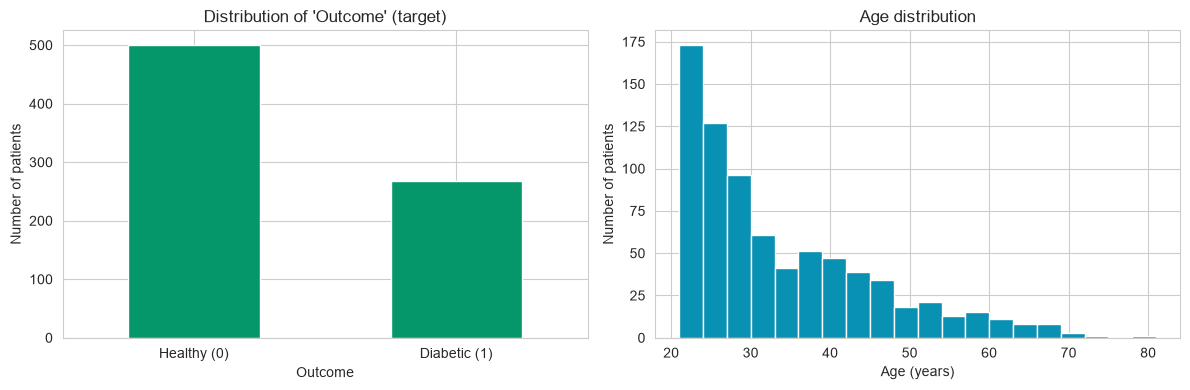

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["Outcome"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#059669")
axes[0].set_title("Distribution of 'Outcome' (target)")
axes[0].set_xticklabels(["Healthy (0)", "Diabetic (1)"], rotation=0)
axes[0].set_ylabel("Number of patients")

df["Age"].plot(kind="hist", bins=20, ax=axes[1], color="#0891b2", edgecolor="white")
axes[1].set_title("Age distribution")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Number of patients")

plt.tight_layout()
plt.show()

## 3. Data preprocessing

**Step 1 — Handle hidden missing values**: zeros in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` are replaced with `NaN`, then imputed with the median.

**Step 2 — Scaling**: `StandardScaler` fitted on training data only (no leakage).

In [8]:
# Replace zeros with NaN (hidden missing values)
cols_with_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

print("Missing values after replacing zeros:")
print(df.isnull().sum())

# Impute with median
for col in df.columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

print(f"\nRemaining missing values: {df.isnull().sum().sum()}")
print(f"Final shape: {df.shape}")

Missing values after replacing zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Remaining missing values: 0
Final shape: (768, 9)


## 4. Train/test split and scaling

80% train / 20% test, stratified on `Outcome` to preserve the diabetic/healthy ratio.

In [9]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")

Training set: (614, 8)
Test set:     (154, 8)


## 5. Training and comparing 4 models

Same 4 algorithms as in the Heart Disease project: Logistic Regression, SVM (RBF), Random Forest, XGBoost.

Metrics: Accuracy, Precision, Recall, F1-Score, ROC-AUC.

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "SVM (RBF)": CalibratedClassifierCV(SVC(random_state=RANDOM_STATE), ensemble=False, cv=5),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=4,
        eval_metric="logloss", random_state=RANDOM_STATE
    ),
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\n{'=' * 55}\n{name}\n{'=' * 55}")
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

    print(classification_report(y_test, y_pred, target_names=["Healthy", "Diabetic"]))


Logistic Regression
              precision    recall  f1-score   support

     Healthy       0.75      0.82      0.78       100
    Diabetic       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154


SVM (RBF)
              precision    recall  f1-score   support

     Healthy       0.78      0.84      0.81       100
    Diabetic       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154


Random Forest
              precision    recall  f1-score   support

     Healthy       0.78      0.84      0.81       100
    Diabetic       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73    

In [11]:
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
results_df.to_csv("results.csv", index=False)

print("Model comparison:")
results_df.round(4)

Model comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,XGBoost,0.7597,0.6735,0.6111,0.6408,0.8270
2,Random Forest,0.7403,0.6522,0.5556,0.6000,0.8161
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130
1,SVM (RBF),0.7403,0.6522,0.5556,0.6000,0.7963


In [12]:
# Save best model, scaler, features for Streamlit app
import joblib

best_model_name = results_df.iloc[0]["Model"]
print(f"Best model: {best_model_name}")

joblib.dump(trained_models[best_model_name], "model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "features.pkl")

print(f"Saved: model.pkl, scaler.pkl, features.pkl")

Best model: XGBoost
Saved: model.pkl, scaler.pkl, features.pkl


## 6. Visualizations

### 6.1 Model comparison

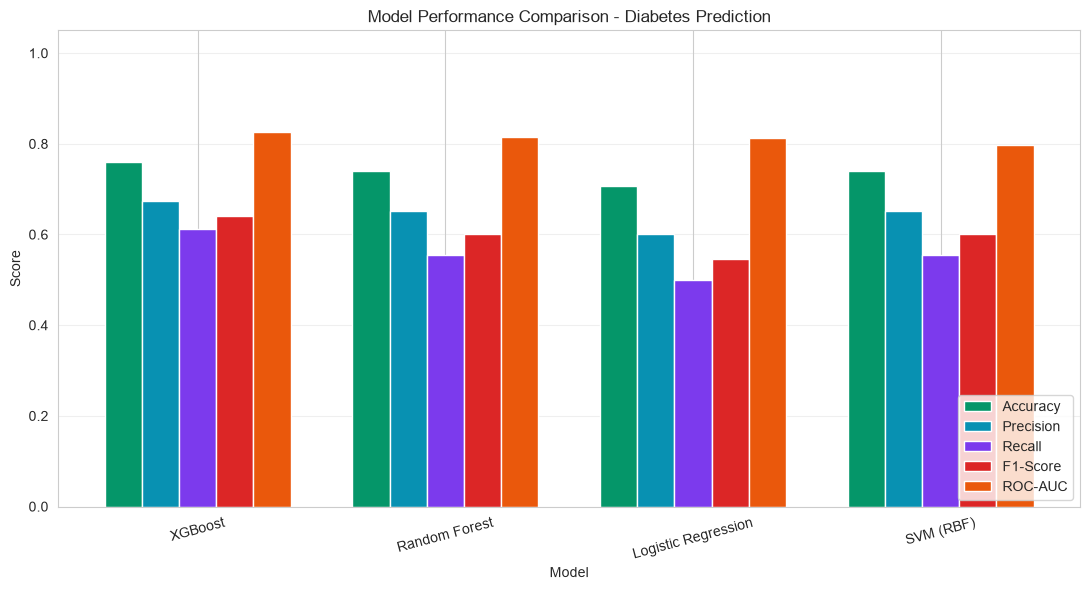

In [13]:
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(results_df))
width = 0.15
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
colors = ["#059669", "#0891b2", "#7c3aed", "#dc2626", "#ea580c"]

for i, (metric, color) in enumerate(zip(metrics, colors)):
    ax.bar(x + i * width, results_df[metric], width, label=metric, color=color)

ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_title("Model Performance Comparison - Diabetes Prediction")
ax.set_xticks(x + width * 2)
ax.set_xticklabels(results_df["Model"], rotation=15)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Confusion matrices

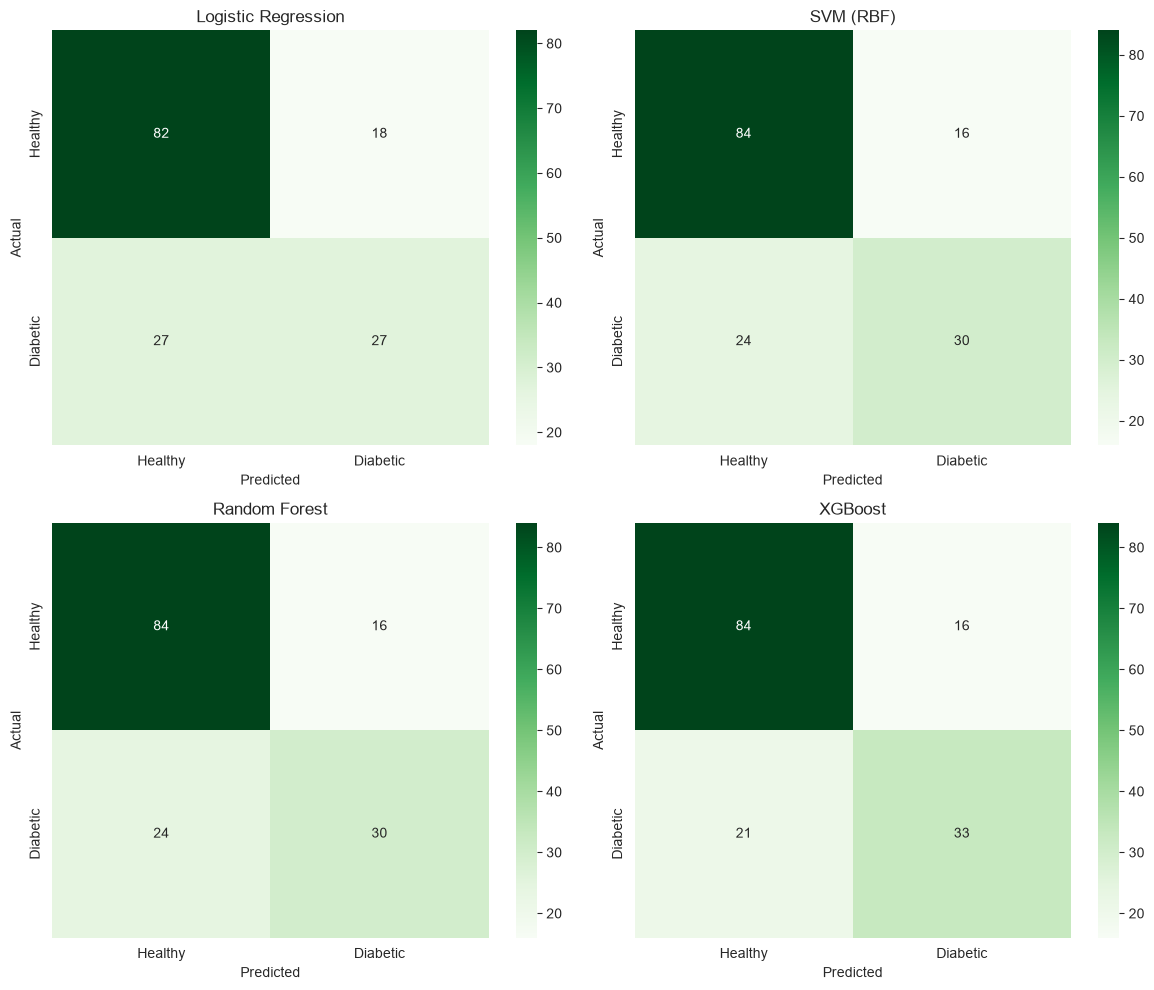

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, model) in zip(axes.ravel(), trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", ax=ax,
                xticklabels=["Healthy", "Diabetic"],
                yticklabels=["Healthy", "Diabetic"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4 Feature importance (Random Forest)

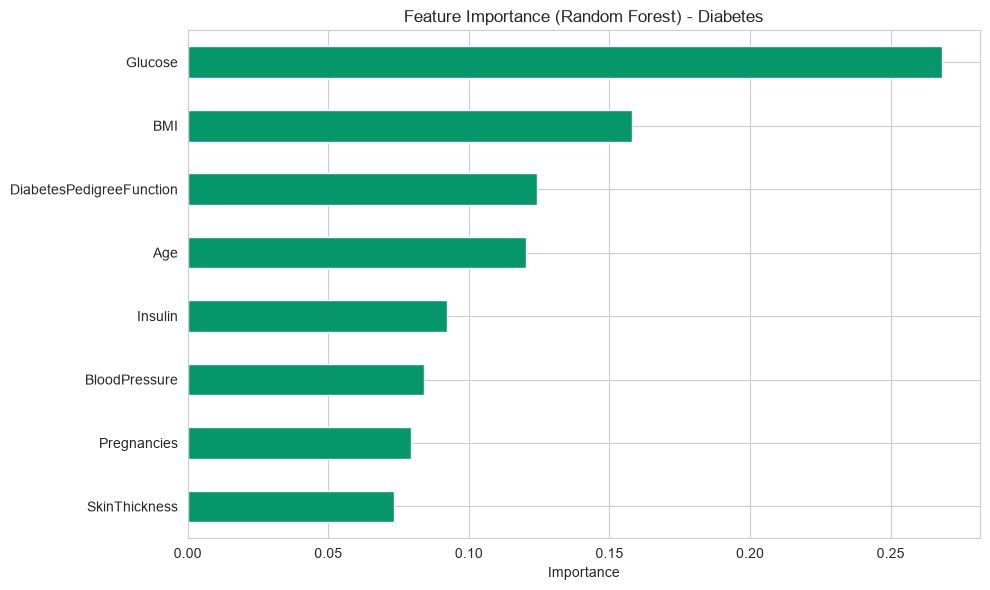

Feature importances:
Glucose                     0.2684
BMI                         0.1581
DiabetesPedigreeFunction    0.1244
Age                         0.1203
Insulin                     0.0923
BloodPressure               0.0839
Pregnancies                 0.0794
SkinThickness               0.0732
dtype: float64


In [15]:
rf = trained_models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
importances.plot(kind="barh", ax=ax, color="#059669")
ax.set_xlabel("Importance")
ax.set_title("Feature Importance (Random Forest) - Diabetes")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Feature importances:")
print(importances.round(4))

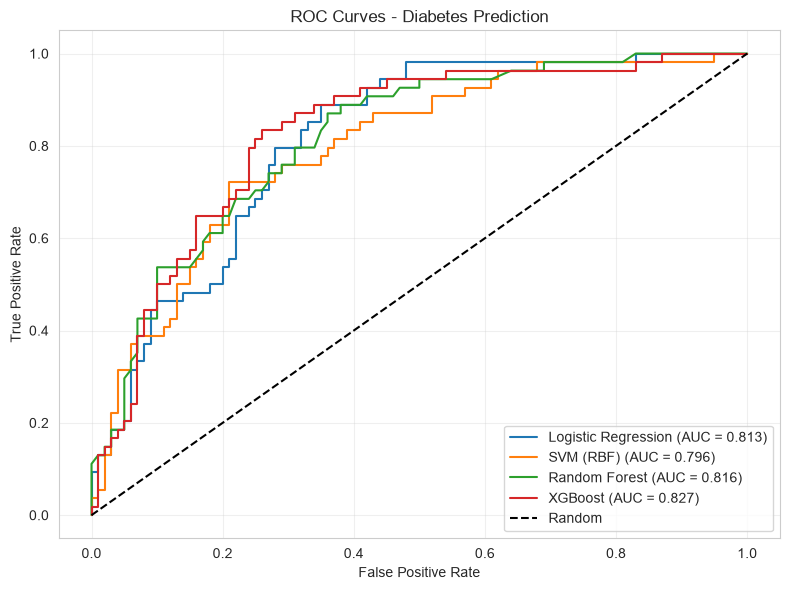

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves - Diabetes Prediction")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Conclusion

The Pima Indians Diabetes dataset is **noticeably harder** than the Heart Disease dataset — and this is expected for three reasons:

- **Hidden missing values**: up to 48.7% of `Insulin` and 29.6% of `SkinThickness` values were encoded as zeros and had to be imputed.
- **Smaller dataset**: 768 patients vs. 920 for Heart Disease.
- **Class imbalance**: 65% healthy vs. 35% diabetic.

### Final results

| Model | Accuracy | F1-Score | ROC-AUC |
|---|---|---|---|
| **XGBoost** ⭐ | **0.7597** | **0.6408** | **0.8270** |
| Random Forest | 0.7403 | 0.6000 | 0.8161 |
| Logistic Regression | 0.7078 | 0.5455 | 0.8130 |
| SVM (RBF) | 0.7403 | 0.6000 | 0.7963 |

**XGBoost** was selected as the best model (ROC-AUC = 0.827). Interestingly, unlike Heart Disease where SVM won, **gradient boosting outperformed here** — a known phenomenon for small tabular datasets with significant missing values.

### Key insights

- The **class imbalance** (35% diabetic) explains why recall for the diabetic class is lower (~60%) — the model favors the majority class.
- **Glucose** is typically the strongest predictor, followed by **BMI** and **Age** — consistent with medical literature on type 2 diabetes risk factors.

### Limitations and future work

- Apply **SMOTE** or **class weighting** to improve diabetic recall.
- Try **feature engineering**: BMI × Age, Glucose × Insulin ratio.
- Use **k-fold cross-validation** for more robust estimates.
- Deploy alongside Heart Disease in a unified health-risk dashboard.

---

*Project completed as part of the Machine Learning Internship at [CodeAlpha](https://www.codealpha.tech).*